# Parametric non-intrusive reduced-order models

In this notebook, we construct and compare three non-intrusive reduced-order models (ROMs) for a parametric problem, where the parameter is the Péclet number $Pe$.

The goal is to predict the solution at a fixed time $t=T_{\mathrm{eval}}$ for parameter values that were not used during training.

We compare three regression methods:

- **Radial basis function interpolation (RBF)**
- **Artificial neural networks (ANN)**
- **Gaussian process regression (GPR)**

All three methods use the same reduced representation of the solution, obtained through proper orthogonal decomposition (POD). They differ only in how they predict the reduced coefficients from the parameter.

The workflow is:

1. Load one snapshot at the target time from each parameter trajectory.
2. Split the parameter values into training and test sets.
3. Compute a POD basis using only the training snapshots.
4. Train the regression models to predict the POD coefficients.
5. Evaluate the ROMs on unseen parameter values and compare their errors.

In [ ]:
import time
import numpy as np
import scipy.sparse as sp
import scipy.sparse.linalg as spla

# Parameters
n_el, T, dt, Pe = 1000, 0.5, 1e-6, 100
x0, w0 = 0.2, 0.01

h, n = 1 / n_el, n_el - 1
x = np.linspace(0, 1, n_el + 1)[1:-1]

def tri(a, b, c):
    return sp.diags([a, b, c], [-1, 0, 1], shape=(n, n), format="csc")

M = h / 6 * tri(1, 4, 1)
K = 1 / h * tri(-1, 2, -1)
C = 0.5 * tri(-1, 0, 1)
M_solve = spla.splu(M).solve

assert dt <= h**2 * Pe / 6
assert Pe * h / 2 <= 1

u = np.exp(-((x - x0) / w0)**2)
n_steps = round(T / dt)

start = time.perf_counter()

for _ in range(n_steps):
    C_u = C @ sp.diags(u)
    A_u = K / Pe + C_u
    u -= dt * M_solve(A_u @ u)

fom_time = time.perf_counter() - start
print(f"FOM runtime (Pe={Pe}): {fom_time:.3f} s")

KeyboardInterrupt: 

In [79]:
import glob
import os
import time
import numpy as np
import scipy.sparse as sp
import scipy.linalg as la
import matplotlib.pyplot as plt
from scipy.interpolate import RBFInterpolator
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.exceptions import ConvergenceWarning
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, Matern, WhiteKernel
import warnings
warnings.filterwarnings("ignore")

fom_time = 180.0
# ------------------------------------------------------------
# Parameters
# ------------------------------------------------------------
T_eval = 0.5
energy_target = 0.999999
test_indices = [10, 20, 50, 60, 70]  # held-out parameter indices

M = sp.load_npz("M.npz").toarray()

## 1. Dataset and training/test split

Each trajectory contains the solution snapshots $u(t;Pe)$ associated with one Péclet number. We extract the snapshot closest to the prescribed evaluation time $T_{\mathrm{eval}}$.

The resulting snapshot matrix is

$
S =
\begin{bmatrix}
| & | & & |\\
u(Pe_1) & u(Pe_2) & \cdots & u(Pe_{n_s})\\
| & | & & |
\end{bmatrix}
\in\mathbb{R}^{N_h\times n_s},
$

where $N_h$ is the number of spatial degrees of freedom and $n_s$ is the number of parameter values.

We split the snapshots into a **training set** and a **test set**. The training set is used to construct the POD basis and fit the regression models, while the test set is reserved for evaluating their predictive performance.

To account for the potentially large range of Péclet numbers, we use the logarithmic parameter

$
\mu=\log_{10}(Pe).
$

This transformation often provides a more suitable coordinate for regression when the parameter spans several orders of magnitude.

In [80]:
# ------------------------------------------------------------
# Load one snapshot at t = T_eval from each trajectory
# ------------------------------------------------------------
files = sorted(glob.glob("./snapshots/trajectory_*.npz"))

data = []
for filename in files:
    with np.load(filename) as d:
        if "Pe" not in d.files:
            continue

        Pe = float(d["Pe"])
        S = d["S"]
        t = d["t"]
        x = d["x"]

        i = np.argmin(np.abs(t - T_eval))
        if abs(t[i] - T_eval) > 1e-9:
            print(f"Skipping {filename}: no snapshot at t={T_eval}")
            continue

        data.append((Pe, S[:, i].copy(), x.copy(), filename))

data.sort(key=lambda item: item[0])

if len(data) < 5:
    raise ValueError(f"Only {len(data)} usable trajectories found.")

Pe_all = np.array([d[0] for d in data])
S_all = np.column_stack([d[1] for d in data])
x = data[0][2]

if S_all.shape[0] != M.shape[0]:
    raise ValueError(f"Snapshot/M dimensions differ: {S_all.shape}, {M.shape}")

# Parameter is represented on a logarithmic scale.
mu_all = np.log10(Pe_all)

test_indices = np.asarray(test_indices, dtype=int)
if np.any(test_indices >= len(Pe_all)):
    raise ValueError("Some test indices exceed the number of trajectories.")

train_mask = np.ones(len(Pe_all), dtype=bool)
train_mask[test_indices] = False
train_idx = np.flatnonzero(train_mask)

Pe_train, Pe_test = Pe_all[train_idx], Pe_all[test_indices]
mu_train, mu_test = mu_all[train_idx], mu_all[test_indices]
S_train, S_test = S_all[:, train_idx], S_all[:, test_indices]

print(f"Trajectories: {len(Pe_all)}")
print(f"Training parameters: {len(train_idx)}")
print(f"Testing parameters: {len(test_indices)}")
print(f"Training Pe: {Pe_train}")
print(f"Testing Pe:  {Pe_test}")

Trajectories: 81
Training parameters: 76
Testing parameters: 5
Training Pe: [  10.           10.59253725   11.22018454   11.88502227   12.58925412
   13.33521432   14.12537545   14.96235656   15.84893192   16.78804018
   18.83649089   19.95262315   21.1348904    22.38721139   23.71373706
   25.11886432   26.6072506    28.18382931   29.85382619   33.49654392
   35.48133892   37.58374043   39.81071706   42.16965034   44.66835922
   47.3151259    50.11872336   53.08844442   56.23413252   59.56621435
   63.09573445   66.83439176   70.79457844   74.98942093   79.43282347
   84.13951416   89.12509381   94.40608763  100.          105.92537252
  112.20184543  118.85022274  125.89254118  133.35214322  141.25375446
  149.62356561  158.48931925  167.88040181  188.36490895  199.5262315
  211.34890398  223.87211386  237.13737057  251.18864315  266.07250598
  281.83829313  298.53826189  334.96543916  354.81338923  375.83740429
  398.10717055  421.69650343  446.68359215  473.15125896  501.18723363
  

## 2. Proper Orthogonal Decomposition

POD constructs a low-dimensional basis that captures the dominant energetic structures in the snapshot ensemble.

For the snapshot matrix $S=[u_1,\ldots,u_{n_s}]$, we solve the snapshot correlation eigenproblem

$
S^\top M S\,w_i=\lambda_i w_i.
$

The corresponding spatial modes are

$
\phi_i=\frac{S w_i}{\sqrt{\lambda_i}}.
$

The modes are orthonormal in the mass-matrix inner product,$\Phi^\top M\Phi=I$.

We retain the smallest number of modes that reaches the prescribed cumulative energy threshold.

In [81]:
# ------------------------------------------------------------
# POD basis: constructed from training parameters only
# ------------------------------------------------------------
def pod(S, energy_target):
    lam, W = la.eigh(S.T @ M @ S)
    idx = np.argsort(lam)[::-1]
    lam, W = lam[idx], W[:, idx]

    keep = lam > 1e-14 * lam[0]
    lam, W = lam[keep], W[:, keep]

    energy = np.cumsum(lam) / lam.sum()
    N = np.searchsorted(energy, energy_target) + 1
    Z = S @ (W[:, :N] / np.sqrt(lam[:N]))

    return Z, N, lam, energy


Z, N, lam, energy = pod(S_train, energy_target)
A_train = Z.T @ M @ S_train

print(f"\nPOD modes: N = {N}")
print(f"Retained energy: {100 * energy[N-1]:.6f}%")


POD modes: N = 9
Retained energy: 99.999978%


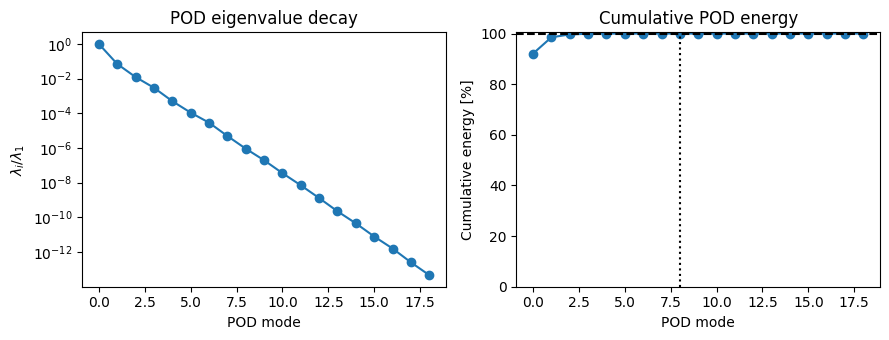

In [82]:
# ------------------------------------------------------------
# Plot 3: POD eigenvalue decay
# ------------------------------------------------------------
fig, axs = plt.subplots(1, 2, figsize=(9, 3.5))

axs[0].semilogy(lam / lam[0], "o-")
axs[0].set_xlabel("POD mode")
axs[0].set_ylabel(r"$\lambda_i/\lambda_1$")
axs[0].set_title("POD eigenvalue decay")

axs[1].plot(100 * energy, "o-")
axs[1].axhline(100 * energy_target, ls="--", color="k")
axs[1].axvline(N - 1, ls=":", color="k")
axs[1].set_xlabel("POD mode")
axs[1].set_ylabel("Cumulative energy [%]")
axs[1].set_ylim(0, 100.5)
axs[1].set_title("Cumulative POD energy")

fig.tight_layout()
plt.show()

## 3. Reduced representation of the solution

Once the POD basis has been computed, we collect its first $N$ modes into the matrix

$
Z=[\zeta_1,\ldots,\zeta_N]
\in\mathbb{R}^{N_h\times N}.
$

The solution is approximated as

$
u(Pe)\approx Z a(Pe),
$

where $a(Pe)\in\mathbb{R}^{N}$ is the vector of reduced coefficients.

Because the POD modes are orthonormal with respect to $M$, the coefficients of a training snapshot are obtained by projection:

$
a(Pe_j)=Z^\top M u(Pe_j).
$

The regression problem is therefore reduced to learning the map

$
\mu=\log_{10}(Pe)\longmapsto a(Pe)
$

Instead of predicting all $N_h$ degrees of freedom directly, each model predicts only $N$ reduced coefficients. The full-order solution is then reconstructed by multiplying the predicted coefficients by the POD basis.

This separation between dimensionality reduction and regression is common to all three non-intrusive ROMs considered here.

## 4. Non-intrusive regression models

We use three regression strategies to approximate the parameter-to-coefficient map,

$
\mu\longmapsto a(\mu).
$

### Radial basis function interpolation (RBF)

RBF interpolation represents the output as a combination of radial basis functions centered at the training parameter values. In this notebook, we use the thin-plate spline kernel.

The interpolant is constructed to reproduce the training coefficients, with a polynomial contribution included by the implementation. This approach is particularly convenient when the parameter space is low-dimensional and the training dataset is relatively small.

### Artificial neural network (ANN)

The neural network learns a nonlinear mapping between the input parameter and the reduced coefficients. We use a multilayer perceptron with two hidden layers, each containing 32 neurons, and a hyperbolic tangent activation function.

The network is trained by minimizing a loss based on the difference between predicted and reference training coefficients. Both the input parameter and the output coefficients are standardized during training to improve numerical conditioning.

### Gaussian process regression (GPR)

Gaussian process regression models the reduced coefficients as functions with a probabilistic prior. Predictions are obtained from the training data and a covariance kernel.

We use a Matérn kernel with smoothness parameter $nu=2.5$, multiplied by a constant amplitude, together with a white-noise term. The kernel hyperparameters are optimized during training.

GPR can also quantify predictive uncertainty, although the present comparison focuses on the predicted mean.

### A fair comparison

All three methods use **the same training parameters, POD basis and reduced coefficients**. Thus, the main difference between the ROMs is the regression method used to approximate the parameter dependence.

In [ ]:
# ------------------------------------------------------------
# Non-intrusive models: log10(Pe) -> POD coefficients
# ------------------------------------------------------------
def fit_rbf(mu_train, A_train):
    model = RBFInterpolator(
        mu_train[:, None],
        A_train.T,
        kernel="thin_plate_spline",
        smoothing=0.0,
    )
    return lambda mu: model(np.atleast_1d(mu)[:, None]).T


def fit_nn(mu_train, A_train, seed=0):
    sx, sy = StandardScaler(), StandardScaler()
    X = sx.fit_transform(mu_train[:, None])
    Y = sy.fit_transform(A_train.T)

    model = MLPRegressor(
        hidden_layer_sizes=(128, 128),
        activation="tanh",
        solver="adam",
        max_iter=5000,
        tol=1e-10,
        random_state=seed,
        verbose=True,
        n_iter_no_change=200,
    )

    with warnings.catch_warnings():
        warnings.simplefilter("ignore", ConvergenceWarning)
        model.fit(X, Y)

    def predict(mu):
        mu = np.atleast_1d(mu)
        Yp = model.predict(sx.transform(mu[:, None]))
        return sy.inverse_transform(Yp.reshape(len(mu), -1)).T

    return predict


def fit_gp(mu_train, A_train):
    sx, sy = StandardScaler(), StandardScaler()
    X = sx.fit_transform(mu_train[:, None])
    Y = sy.fit_transform(A_train.T)

    kernel = (
        ConstantKernel(1.0, (1e-2, 1e2))
        * Matern(
            length_scale=0.3,
            length_scale_bounds=(1e-2, 1e2),
            nu=2.5,
        )
        + WhiteKernel(
            noise_level=1e-6,
            noise_level_bounds=(1e-10, 1e-2),
        )
    )

    model = GaussianProcessRegressor(
        kernel=kernel,
        normalize_y=False,
        n_restarts_optimizer=3,
        random_state=0,
    )
    model.fit(X, Y)

    def predict(mu):
        mu = np.atleast_1d(mu)
        Yp = model.predict(sx.transform(mu[:, None]))
        return sy.inverse_transform(Yp.reshape(len(mu), -1)).T

    return predict

In [112]:
# Fit models using training parameters only.
models = {}
fit_times = {}

for name, fitter in (
    ("POD-RBF", fit_rbf),
    ("POD-NN", fit_nn),
    ("POD-GPR", fit_gp),
):
    start = time.perf_counter()
    models[name] = fitter(mu_train, A_train)
    fit_times[name] = time.perf_counter() - start

Iteration 1, loss = 0.53724920
Iteration 2, loss = 0.47383488
Iteration 3, loss = 0.43182590
Iteration 4, loss = 0.40775845
Iteration 5, loss = 0.39774025
Iteration 6, loss = 0.39794304
Iteration 7, loss = 0.40406950
Iteration 8, loss = 0.41135753
Iteration 9, loss = 0.41608297
Iteration 10, loss = 0.41677932
Iteration 11, loss = 0.41395065
Iteration 12, loss = 0.40903620
Iteration 13, loss = 0.40356946
Iteration 14, loss = 0.39875035
Iteration 15, loss = 0.39531025
Iteration 16, loss = 0.39352127
Iteration 17, loss = 0.39326292
Iteration 18, loss = 0.39412115
Iteration 19, loss = 0.39552542
Iteration 20, loss = 0.39691392
Iteration 21, loss = 0.39787706
Iteration 22, loss = 0.39822288
Iteration 23, loss = 0.39795397
Iteration 24, loss = 0.39719554
Iteration 25, loss = 0.39612354
Iteration 26, loss = 0.39491871
Iteration 27, loss = 0.39374529
Iteration 28, loss = 0.39274018
Iteration 29, loss = 0.39200079
Iteration 30, loss = 0.39157185
Iteration 31, loss = 0.39143741
Iteration 32, los

## 5. Reconstruction and error assessment

For each held-out parameter $Pe^\ast$, the regression model predicts the reduced coefficients,

$
\widehat a(Pe^\ast).
$

The corresponding full-order approximation is reconstructed as

$
u_{\mathrm{ROM}}(Pe^\ast)
=Z\widehat a(Pe^\ast).
$

We evaluate the predictions using the absolute mass-norm error,

$
e(Pe^\ast)=
\left\|u_{\mathrm{FOM}}(Pe^\ast)
-u_{\mathrm{ROM}}(Pe^\ast)\right\|_M.
$

This metric measures the absolute difference between the reference full-order solution and the reconstructed ROM solution, using the finite-element mass matrix to define the norm.

### POD projection error

We also compute the projection of each test snapshot onto the POD space:

$
u_{\mathrm{proj}}(Pe^\ast)
=ZZ^\top M u_{\mathrm{FOM}}(Pe^\ast).
$

Its error is

$
e_{\mathrm{proj}}(Pe^\ast)=
\left\|u_{\mathrm{FOM}}(Pe^\ast)
-u_{\mathrm{proj}}(Pe^\ast)\right\|_M.
$

The projection is the best approximation to the test snapshot in the chosen POD space, measured in the $M$-norm. It therefore provides a reference for interpreting the ROM errors.

The ROM error contains two contributions: the limitation imposed by the finite-dimensional POD space and the error introduced by predicting the reduced coefficients. A large gap between the ROM error and the projection error indicates that the regression model is not accurately reproducing the coefficients needed to represent the test solution.

In [113]:
# ------------------------------------------------------------
# Predict held-out parameters, compute errors and speed-up
# ------------------------------------------------------------
def err_M(u, u_ref):
    d = u - u_ref
    return np.sqrt(max(d @ M @ d, 0.0))


U_pred, errors, predict_times = {}, {}, {}

for name, model in models.items():
    start = time.perf_counter()
    A_pred = model(mu_test)
    U_pred[name] = Z @ A_pred
    predict_times[name] = time.perf_counter() - start

    errors[name] = np.array([
        err_M(S_test[:, j], U_pred[name][:, j])
        for j in range(len(Pe_test))
    ])

    print(f"\n{name}")
    print(f"  Fit time: {fit_times[name]:.4f} s")
    print(f"  Online time (all test parameters): {predict_times[name]:.6f} s")
    print(f"  Online time per parameter: {predict_times[name]/len(Pe_test):.6f} s")
    print(f"  Speed-up (all test parameters): {fom_time/predict_times[name]:.2f}x")
    print(f"  Speed-up (per parameter): {fom_time/(predict_times[name]/len(Pe_test)):.2f}x")

    for Pe, e in zip(Pe_test, errors[name]):
        print(f"  Pe={Pe:8.3f}: absolute M-norm error = {e:.6e}")


# POD projection error
U_proj = Z @ (Z.T @ M @ S_test)
err_proj = np.array([
    err_M(S_test[:, j], U_proj[:, j])
    for j in range(len(Pe_test))
])

print("\nProjection errors (POD truncation floor):")
for Pe, e in zip(Pe_test, err_proj):
    print(f"  Pe={Pe:8.3f}: {e:.6e}")


POD-RBF
  Fit time: 0.0009 s
  Online time (all test parameters): 0.000548 s
  Online time per parameter: 0.000110 s
  Speed-up (all test parameters): 328591.87x
  Speed-up (per parameter): 1642959.35x
  Pe=  17.783: absolute M-norm error = 1.306226e-05
  Pe=  31.623: absolute M-norm error = 1.564567e-05
  Pe= 177.828: absolute M-norm error = 1.401352e-05
  Pe= 316.228: absolute M-norm error = 1.823604e-05
  Pe= 562.341: absolute M-norm error = 2.494397e-05

POD-NN
  Fit time: 4.8256 s
  Online time (all test parameters): 0.001833 s
  Online time per parameter: 0.000367 s
  Speed-up (all test parameters): 98190.78x
  Speed-up (per parameter): 490953.90x
  Pe=  17.783: absolute M-norm error = 2.831312e-05
  Pe=  31.623: absolute M-norm error = 4.354954e-05
  Pe= 177.828: absolute M-norm error = 8.636485e-05
  Pe= 316.228: absolute M-norm error = 6.939677e-05
  Pe= 562.341: absolute M-norm error = 1.504511e-04

POD-GPR
  Fit time: 0.3748 s
  Online time (all test parameters): 0.000785 s

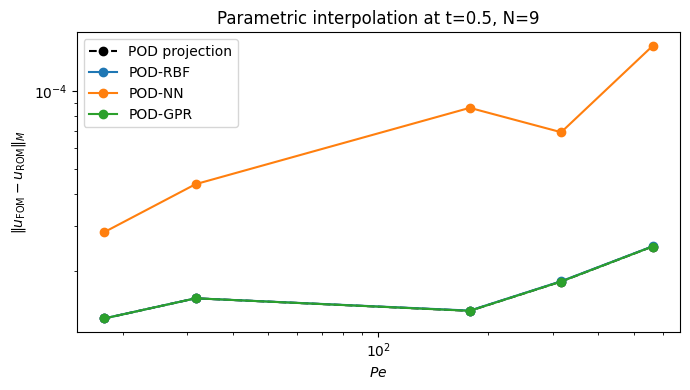

In [114]:
# ------------------------------------------------------------
# Plot 1: errors versus held-out Pe
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(7, 4))
ax.semilogy(Pe_test, err_proj, "ko--", label="POD projection")
for name, e in errors.items():
    ax.semilogy(Pe_test, e, "o-", label=name)

ax.set_xscale("log")
ax.set_xlabel(r"$Pe$")
ax.set_ylabel(r"$\|u_{\mathrm{FOM}}-u_{\mathrm{ROM}}\|_M$")
ax.set_title(f"Parametric interpolation at t={T_eval}, N={N}")
ax.legend()
fig.tight_layout()

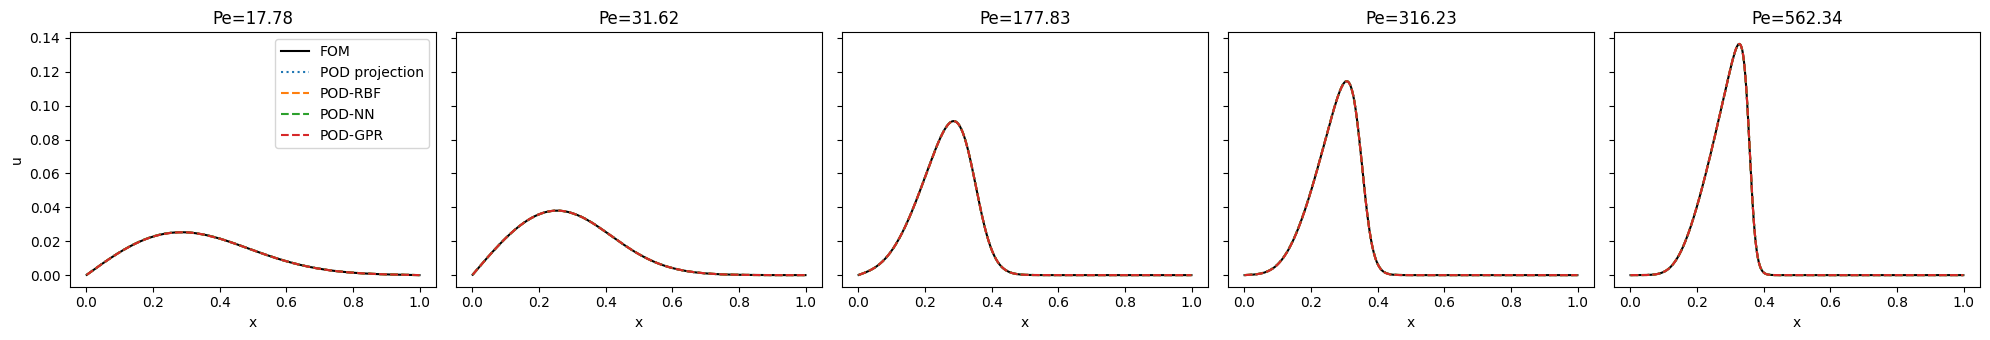

In [87]:
# ------------------------------------------------------------
# Plot 2: FOM and ROM profiles at each held-out Pe
# ------------------------------------------------------------
fig, axs = plt.subplots(
    1, len(Pe_test), figsize=(4 * len(Pe_test), 3.5), sharey=True
)
axs = np.atleast_1d(axs)

for j, ax in enumerate(axs):
    ax.plot(x, S_test[:, j], "k-", label="FOM")
    ax.plot(x, U_proj[:, j], ":", label="POD projection")
    for name, U in U_pred.items():
        ax.plot(x, U[:, j], "--", label=name)

    ax.set_title(f"Pe={Pe_test[j]:.2f}")
    ax.set_xlabel("x")

axs[0].set_ylabel("u")
axs[0].legend()
fig.tight_layout()

In [88]:
# ------------------------------------------------------------
# Convergence study: vary the number of POD modes
# ------------------------------------------------------------
lam_all, W_all = la.eigh(S_train.T @ M @ S_train)
idx = np.argsort(lam_all)[::-1]
lam_all, W_all = lam_all[idx], W_all[:, idx]

keep = lam_all > 1e-14 * lam_all[0]
lam_all, W_all = lam_all[keep], W_all[:, keep]

Z_all = S_train @ (W_all / np.sqrt(lam_all))
energy_all = np.cumsum(lam_all) / lam_all.sum()

N_list = np.arange(1, Z_all.shape[1] + 1)
errors_conv = {name: [] for name in ("POD-RBF", "POD-NN", "POD-GPR")}
errors_proj_conv = []

for n in N_list:
    Z_n = Z_all[:, :n]
    A_n = Z_n.T @ M @ S_train

    # POD projection error
    U_proj_n = Z_n @ (Z_n.T @ M @ S_test)
    e_proj = [err_M(S_test[:, j], U_proj_n[:, j])
              for j in range(len(Pe_test))]
    errors_proj_conv.append(np.mean(e_proj))

    # Train, predict, and evaluate each non-intrusive ROM
    for name, fitter in (
        ("POD-RBF", fit_rbf),
        ("POD-NN", fit_nn),
        ("POD-GPR", fit_gp),
    ):
        model = fitter(mu_train, A_n)
        A_pred = model(mu_test)
        U_pred_n = Z_n @ A_pred

        e = [err_M(S_test[:, j], U_pred_n[:, j])
             for j in range(len(Pe_test))]
        errors_conv[name].append(np.mean(e))

# Plot mean absolute M-norm errors
fig, ax = plt.subplots(figsize=(7, 4))

ax.semilogy(N_list, errors_proj_conv, "ko--", label="POD projection")
for name, e in errors_conv.items():
    ax.semilogy(N_list, e, "o-", label=name)

ax.set_xlabel("Number of POD modes $N$")
ax.set_ylabel("Mean absolute $M$-norm error")
ax.set_title(f"Parametric ROM convergence at $t={T_eval}$")
ax.set_xticks(N_list)
ax.legend()
fig.tight_layout()
plt.show()

KeyboardInterrupt: 